# Entrenamiento de modelos Multicanal

**Maestría en Inteligencia Artificial MAIA**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrenamiento supervisado con `XGBClassifier`, `Random Forest`, `Arbol de Decisiones`y `LightGBM` usando `train_multicanal.csv` y `test_multicanal.csv`. El dataset multicanal conserva un único esquema de columnas para soportar inferencia cuando alguno de los canales `EEG` está presente y `EOG horizontal` opcional. La evaluación se reporta de forma global y por combinación de canales (`channel_combo`).

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.data.segmentation import CLASS_NAMES, INT_TO_CLASS


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

## Configuración

El entrenamiento excluye identificadores y columnas de control que pueden generar fuga de información (`recording_id`, `subject_code`, `split`, `epoch_idx_in_recording`). Sí se conservan las columnas de disponibilidad de canales (`has_eeg_pz_oz`, `has_eog_horizontal`), `channel_count` y una codificación one-hot de `channel_combo`, porque esas variables representan qué señales están disponibles en inferencia.

In [2]:
RANDOM_STATE = 42
CV_SPLITS = 5
N_ITER_SEARCH = 10
SCORING = "f1_macro"

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]
CONTROL_COLUMNS = ["split", "epoch_idx_in_recording"]
CATEGORICAL_COLUMNS = ["channel_combo"]

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train_multicanal.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

TRAIN_PATH = DATA_DIR / "train_multicanal.csv"
TEST_PATH = DATA_DIR / "test_multicanal.csv"

COMPARISON_PATH = MODEL_DIR / "model_comparison_multicanal.csv"
COMPARISON_BY_COMBO_PATH = MODEL_DIR / "model_comparison_by_channel_combo_multicanal.csv"


def get_artifact_paths(model_slug):
    """Rutas de artefactos de un modelo, p. ej. `best-xgboost-multicanal.joblib`."""
    return {
        "joblib": MODEL_DIR / f"best-{model_slug}-multicanal.joblib",
        "info": MODEL_DIR / f"model_info_{model_slug}_multicanal.json",
        "metrics_by_combo": MODEL_DIR / f"metrics_by_channel_combo_{model_slug}_multicanal.csv",
        "per_class_by_combo": MODEL_DIR / f"per_class_metrics_by_channel_combo_{model_slug}_multicanal.csv",
        "feature_importance": MODEL_DIR / f"feature_importance_{model_slug}_multicanal.csv",
    }

## Carga de datos

In [3]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

display(train_df.head())
display(train_df[TARGET_COLUMN].value_counts().sort_index().rename("train_count"))
display(test_df[TARGET_COLUMN].value_counts().sort_index().rename("test_count"))
display(train_df["channel_combo"].value_counts().rename("train_rows_by_combo"))
display(test_df["channel_combo"].value_counts().rename("test_rows_by_combo"))

Train shape: (901632, 52)
Test shape:  (271242, 52)


,channel_combo,channel_count,split,epoch_idx_in_recording,has_eeg_fpz_cz,has_eeg_pz_oz,has_eog_horizontal,recording_id,subject_code,y,...,EOG_horizontal__delta_alpha_ratio,EOG_horizontal__delta_power_abs,EOG_horizontal__delta_power_rel,EOG_horizontal__sef95,EOG_horizontal__sigma_power_abs,EOG_horizontal__sigma_power_rel,EOG_horizontal__spectral_entropy,EOG_horizontal__theta_alpha_ratio,EOG_horizontal__theta_power_abs,EOG_horizontal__theta_power_rel
0,eeg_fpz_cz,1,train,0,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,eeg_fpz_cz,1,train,1,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,eeg_fpz_cz,1,train,2,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,eeg_fpz_cz,1,train,3,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,eeg_fpz_cz,1,train,4,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


y
N1      98670
N2     321558
N3      63474
REM    120540
W      297390
Name: train_count, dtype: int64

y
N1     30462
N2     93234
N3     14760
REM    34470
W      98316
Name: test_count, dtype: int64

channel_combo
eeg_fpz_cz                               150272
eeg_pz_oz                                150272
eeg_fpz_cz__eeg_pz_oz                    150272
eeg_fpz_cz__eog_horizontal               150272
eeg_pz_oz__eog_horizontal                150272
eeg_fpz_cz__eeg_pz_oz__eog_horizontal    150272
Name: train_rows_by_combo, dtype: int64

channel_combo
eeg_fpz_cz                               45207
eeg_pz_oz                                45207
eeg_fpz_cz__eeg_pz_oz                    45207
eeg_fpz_cz__eog_horizontal               45207
eeg_pz_oz__eog_horizontal                45207
eeg_fpz_cz__eeg_pz_oz__eog_horizontal    45207
Name: test_rows_by_combo, dtype: int64

## Preparación de matrices

In [4]:
missing_columns = set(train_df.columns) ^ set(test_df.columns)
if missing_columns:
    raise ValueError(f"Train y test no tienen las mismas columnas: {missing_columns}")

excluded_columns = [TARGET_COLUMN, *ID_COLUMNS, *CONTROL_COLUMNS]
base_feature_columns = [column for column in train_df.columns if column not in excluded_columns]

X_train_raw = train_df[base_feature_columns].copy()
X_test_raw = test_df[base_feature_columns].copy()

X_train = pd.get_dummies(X_train_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_test = pd.get_dummies(X_test_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

for df in (X_train, X_test):
    bool_columns = df.select_dtypes(include="bool").columns
    df[bool_columns] = df[bool_columns].astype(np.int8)

feature_columns = X_train.columns.tolist()

y_train_names = train_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(train_df[TARGET_COLUMN]).astype(str)
y_test_names = test_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(test_df[TARGET_COLUMN]).astype(str)

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_NAMES)
y_train = label_encoder.transform(y_train_names)
y_test = label_encoder.transform(y_test_names)
class_labels = np.array(CLASS_NAMES)

groups = train_df["subject_code"].astype(str).to_numpy()
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Número de features: {len(feature_columns)}")
print(f"Clases: {class_labels.tolist()}")
print(f"Número de pacientes/grupos en train: {pd.Series(groups).nunique()}")
print(f"Columnas excluidas: {excluded_columns}")
display(pd.Series(feature_columns, name="features"))

Número de features: 52
Clases: ['W', 'N1', 'N2', 'N3', 'REM']
Número de pacientes/grupos en train: 62
Columnas excluidas: ['y', 'recording_id', 'subject_code', 'split', 'epoch_idx_in_recording']


0                                         channel_count
1                                        has_eeg_fpz_cz
2                                         has_eeg_pz_oz
3                                    has_eog_horizontal
4                           EEG_Fpz-Cz__alpha_power_abs
5                           EEG_Fpz-Cz__alpha_power_rel
6                            EEG_Fpz-Cz__beta_power_abs
7                            EEG_Fpz-Cz__beta_power_rel
8                         EEG_Fpz-Cz__delta_alpha_ratio
9                           EEG_Fpz-Cz__delta_power_abs
10                          EEG_Fpz-Cz__delta_power_rel
11                                    EEG_Fpz-Cz__sef95
12                          EEG_Fpz-Cz__sigma_power_abs
13                          EEG_Fpz-Cz__sigma_power_rel
14                         EEG_Fpz-Cz__spectral_entropy
15                        EEG_Fpz-Cz__theta_alpha_ratio
16                          EEG_Fpz-Cz__theta_power_abs
17                          EEG_Fpz-Cz__theta_po

In [5]:
X_train.head()

,channel_count,has_eeg_fpz_cz,has_eeg_pz_oz,has_eog_horizontal,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__delta_power_abs,...,EOG_horizontal__spectral_entropy,EOG_horizontal__theta_alpha_ratio,EOG_horizontal__theta_power_abs,EOG_horizontal__theta_power_rel,channel_combo_eeg_fpz_cz,channel_combo_eeg_fpz_cz__eeg_pz_oz,channel_combo_eeg_fpz_cz__eeg_pz_oz__eog_horizontal,channel_combo_eeg_fpz_cz__eog_horizontal,channel_combo_eeg_pz_oz,channel_combo_eeg_pz_oz__eog_horizontal
0,1,1,0,0,5.486738,0.013604,9.560419,0.023705,63.606533,348.99237,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0
1,1,1,0,0,4.664630,0.008347,9.769751,0.017481,105.300140,491.18613,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0
2,1,1,0,0,5.123155,0.006255,7.658113,0.009350,142.967540,732.44480,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0
3,1,1,0,0,6.026664,0.009737,15.199880,0.024557,89.450554,539.08844,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0
4,1,1,0,0,5.224161,0.010322,9.270859,0.018317,84.824066,443.13455,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0


## Búsqueda de hiperparámetros con validación cruzada

Los cuatro modelos (`XGBoost`, `LightGBM`, `Random Forest` y `Árbol de Decisión`) se entrenan con el mismo protocolo para que la comparación sea justa:

- `RandomizedSearchCV` con `N_ITER_SEARCH` combinaciones por modelo.
- CV estratificada por clase y agrupada por `subject_code` (`StratifiedGroupKFold`). Así, todas las épocas de un mismo paciente quedan completas en train o validation dentro de cada fold. Los folds son idénticos para todos los modelos.
- Pesos de muestra balanceados (`sample_weight`) para compensar el desbalance de clases.
- Selección del mejor modelo por `f1_macro` y evaluación final en `test_multicanal.csv`.

Las funciones siguientes encapsulan la búsqueda, la evaluación y el guardado de artefactos, para aplicar exactamente el mismo flujo a cada modelo.

In [6]:
cv = StratifiedGroupKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

LABEL_IDS = label_encoder.transform(class_labels)
CV_SUMMARY_COLUMNS = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "params",
]

# Resultados de cada modelo para la comparación final.
results = {}


def run_search(model_name, estimator, param_distributions):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        n_iter=N_ITER_SEARCH,
        scoring=SCORING,
        cv=cv,
        verbose=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train, groups=groups, sample_weight=sample_weights)

    print(f"[{model_name}] Mejor {SCORING} CV: {search.best_score_}")
    print("Mejores hiperparámetros:")
    display(search.best_params_)
    return search


def show_cv_results(search, top_n=10):
    cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    display(cv_results[CV_SUMMARY_COLUMNS].head(top_n))
    return cv_results

In [7]:
def evaluate_predictions(y_true, y_hat, labels, prefix=None):
    return {
        "channel_combo": prefix,
        "support": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_hat),
        "macro_f1": f1_score(y_true, y_hat, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_hat),
        "cohens_kappa": cohen_kappa_score(y_true, y_hat),
    }


def evaluate_global(model_name, search):
    y_pred = search.best_estimator_.predict(X_test)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=LABEL_IDS,
        zero_division=0,
    )

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "cohens_kappa": cohen_kappa_score(y_test, y_pred),
        "best_cv_macro_f1": search.best_score_,
        "best_params": search.best_params_,
    }

    per_class_metrics = pd.DataFrame(
        {
            "class": class_labels,
            "precision_per_class": precision,
            "recall_per_class": recall,
            "f1_per_class": f1,
            "support": support,
        }
    )

    print(f"=== {model_name} - evaluación global en test ===")
    display(pd.Series(metrics, name="value"))
    display(per_class_metrics)
    print(classification_report(y_test, y_pred, target_names=[str(label) for label in class_labels], zero_division=0))
    return y_pred, metrics, per_class_metrics


def evaluate_by_combo(model_name, y_pred):
    combo_metric_rows = []
    combo_per_class_rows = []

    test_eval_df = test_df[["channel_combo", "recording_id", "subject_code", TARGET_COLUMN]].copy()
    test_eval_df["y_true"] = y_test
    test_eval_df["y_pred"] = y_pred

    combo_metric_rows.append(evaluate_predictions(y_test, y_pred, LABEL_IDS, prefix="overall"))

    for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
        combo_y_true = combo_df["y_true"].to_numpy()
        combo_y_pred = combo_df["y_pred"].to_numpy()
        combo_metric_rows.append(evaluate_predictions(combo_y_true, combo_y_pred, LABEL_IDS, prefix=combo_name))

        p, r, f, s = precision_recall_fscore_support(
            combo_y_true,
            combo_y_pred,
            labels=LABEL_IDS,
            zero_division=0,
        )
        for class_name, precision_i, recall_i, f1_i, support_i in zip(class_labels, p, r, f, s):
            combo_per_class_rows.append(
                {
                    "channel_combo": combo_name,
                    "class": class_name,
                    "precision_per_class": precision_i,
                    "recall_per_class": recall_i,
                    "f1_per_class": f1_i,
                    "support": support_i,
                }
            )

    metrics_by_combo = pd.DataFrame(combo_metric_rows).sort_values("channel_combo")
    per_class_by_combo = pd.DataFrame(combo_per_class_rows).sort_values(["channel_combo", "class"])

    display(metrics_by_combo)
    display(per_class_by_combo)

    plt.figure(figsize=(10, 5))
    sns.barplot(data=metrics_by_combo[metrics_by_combo["channel_combo"] != "overall"], x="channel_combo", y="macro_f1", color="#4C78A8")
    plt.title(f"Macro F1 por combinación de canales - {model_name}")
    plt.xlabel("Combinación de canales")
    plt.ylabel("Macro F1")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()
    return test_eval_df, metrics_by_combo, per_class_by_combo


def plot_confusion_matrices(model_name, test_eval_df):
    conf_matrix = confusion_matrix(test_eval_df["y_true"], test_eval_df["y_pred"], labels=LABEL_IDS)
    conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Matriz de confusión global - {model_name} multicanal")
    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.tight_layout()
    plt.show()
    display(conf_matrix_df)

    for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
        combo_conf_matrix = confusion_matrix(
            combo_df["y_true"],
            combo_df["y_pred"],
            labels=LABEL_IDS,
        )
        combo_conf_matrix_df = pd.DataFrame(combo_conf_matrix, index=class_labels, columns=class_labels)
        plt.figure(figsize=(7, 5))
        sns.heatmap(combo_conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
        plt.title(f"Matriz de confusión - {model_name} - {combo_name}")
        plt.xlabel("Predicción")
        plt.ylabel("Clase real")
        plt.tight_layout()
        plt.show()
        display(combo_conf_matrix_df)


def plot_feature_importance(model_name, model, top_n=30):
    feature_importance = pd.DataFrame(
        {
            "feature": feature_columns,
            "importance": model.feature_importances_,
        }
    ).sort_values("importance", ascending=False)

    plt.figure(figsize=(10, 10))
    sns.barplot(data=feature_importance.head(top_n), x="importance", y="feature", color="#4C78A8")
    plt.title(f"Top {top_n} importancia de variables - {model_name} multicanal")
    plt.xlabel("Importancia")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    display(feature_importance)
    return feature_importance


def save_artifacts(model_name, model_slug, search, metrics, metrics_by_combo, per_class_by_combo, feature_importance):
    paths = get_artifact_paths(model_slug)
    best_model = search.best_estimator_

    joblib.dump(
        {
            "model": best_model,
            "label_encoder": label_encoder,
            "feature_columns": feature_columns,
            "excluded_columns": excluded_columns,
            "categorical_columns": CATEGORICAL_COLUMNS,
            "class_labels": class_labels.tolist(),
        },
        paths["joblib"],
    )

    feature_importance.to_csv(paths["feature_importance"], index=False)
    metrics_by_combo.to_csv(paths["metrics_by_combo"], index=False)
    per_class_by_combo.to_csv(paths["per_class_by_combo"], index=False)

    info = {
        "model": model_name,
        **metrics,
        "feature_columns": feature_columns,
        "excluded_columns": excluded_columns,
        "metrics_by_channel_combo": metrics_by_combo.to_dict(orient="records"),
    }

    with open(paths["info"], "w") as f:
        # default=str cubre valores numpy o None dentro de best_params.
        json.dump(info, f, indent=4, default=str)

    results[model_name] = {
        "slug": model_slug,
        "search": search,
        "metrics": metrics,
        "metrics_by_combo": metrics_by_combo,
    }

    print(f"Pipeline joblib guardado en: {paths['joblib']}")
    print(f"Info guardada en: {paths['info']}")
    print(f"Métricas por combinación guardadas en: {paths['metrics_by_combo']}")
    return paths

## Modelo 1: XGBoost

Gradient boosting con árboles (`tree_method="hist"`). Se exploran número de árboles, profundidad, tasa de aprendizaje y regularización.

### Búsqueda de hiperparámetros

In [8]:
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_labels),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

xgb_param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
}

xgb_search = run_search("XGBoost", xgb_model, xgb_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.3min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.3min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.3min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.3min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.3min
[CV] END gamma=0.5, learning_rate=0.08, max_depth

{'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.08, 'gamma': 0}

In [9]:
xgb_cv_results = show_cv_results(xgb_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
1,1,0.684856,0.014398,0.789611,0.002669,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
3,2,0.684152,0.015795,0.807400,0.002471,"{'n_estimators': 700, 'max_depth': 6, 'learnin..."
9,3,0.684118,0.014063,0.768247,0.002905,"{'n_estimators': 500, 'max_depth': 5, 'learnin..."
2,4,0.683094,0.016224,0.814885,0.002521,"{'n_estimators': 500, 'max_depth': 6, 'learnin..."
8,5,0.682751,0.012769,0.752457,0.003305,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
5,6,0.681177,0.016645,0.827562,0.002286,"{'n_estimators': 500, 'max_depth': 6, 'learnin..."
6,7,0.679881,0.016701,0.845070,0.002660,"{'n_estimators': 300, 'max_depth': 8, 'learnin..."
0,8,0.676779,0.012071,0.725261,0.004001,"{'n_estimators': 300, 'max_depth': 3, 'learnin..."
7,9,0.657174,0.009004,0.695864,0.003824,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."
4,10,0.623242,0.007227,0.653015,0.006644,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."


### Evaluación global en test y por combinación de canales

=== XGBoost - evaluación global en test ===


accuracy                                                      0.712721
macro_f1                                                      0.653642
balanced_accuracy                                             0.696683
cohens_kappa                                                  0.613881
best_cv_macro_f1                                              0.684856
best_params          {'n_estimators': 300, 'max_depth': 6, 'learnin...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.875919,0.849699,0.862610,98316
1,N1,0.326854,0.465925,0.384192,30462
2,N2,0.889458,0.652444,0.752735,93234
3,N3,0.572760,0.886653,0.695950,14760
4,REM,0.525906,0.628692,0.572724,34470


              precision    recall  f1-score   support

           W       0.33      0.47      0.38     30462
          N1       0.89      0.65      0.75     93234
          N2       0.57      0.89      0.70     14760
          N3       0.53      0.63      0.57     34470
         REM       0.88      0.85      0.86     98316

    accuracy                           0.71    271242
   macro avg       0.64      0.70      0.65    271242
weighted avg       0.76      0.71      0.73    271242



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,45207,0.665428,0.607002,0.657695,0.553581
2,eeg_fpz_cz__eeg_pz_oz,45207,0.725419,0.666974,0.704712,0.630367
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,45207,0.761254,0.709910,0.748862,0.677268
4,eeg_fpz_cz__eog_horizontal,45207,0.737983,0.685070,0.729878,0.646855
5,eeg_pz_oz,45207,0.663658,0.587822,0.630175,0.549128
6,eeg_pz_oz__eog_horizontal,45207,0.722587,0.667246,0.708774,0.627176
0,overall,271242,0.712721,0.653642,0.696683,0.613881


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.299973,0.430963,0.353730,5077
2,eeg_fpz_cz,N2,0.886806,0.624171,0.732664,15539
3,eeg_fpz_cz,N3,0.525293,0.911789,0.666568,2460
4,eeg_fpz_cz,REM,0.422649,0.535944,0.472602,5745
0,eeg_fpz_cz,W,0.834771,0.785610,0.809444,16386
6,eeg_fpz_cz__eeg_pz_oz,N1,0.326145,0.509356,0.397663,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.900872,0.664972,0.765152,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.621766,0.898780,0.735040,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.528638,0.573542,0.550175,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.896997,0.876907,0.886838,16386


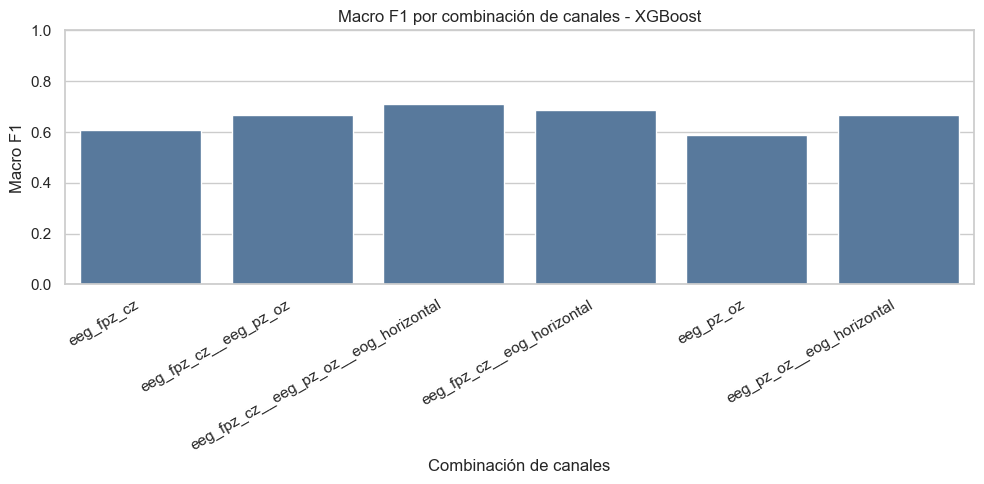

In [10]:
xgb_y_pred, xgb_metrics, xgb_per_class = evaluate_global("XGBoost", xgb_search)
xgb_test_eval_df, xgb_metrics_by_combo, xgb_per_class_by_combo = evaluate_by_combo("XGBoost", xgb_y_pred)

### Matriz de confusión global y por combinación

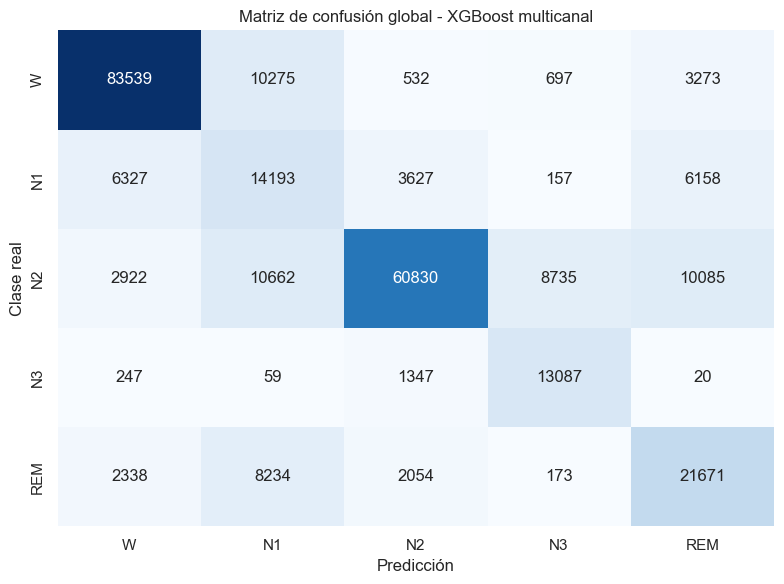

,W,N1,N2,N3,REM
W,83539,10275,532,697,3273
N1,6327,14193,3627,157,6158
N2,2922,10662,60830,8735,10085
N3,247,59,1347,13087,20
REM,2338,8234,2054,173,21671


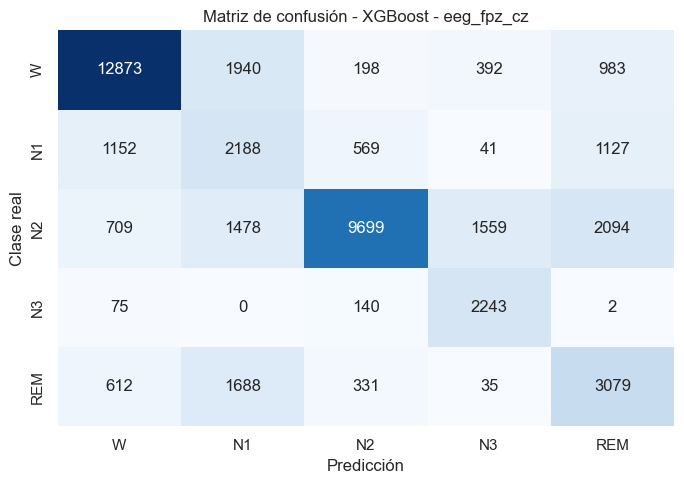

,W,N1,N2,N3,REM
W,12873,1940,198,392,983
N1,1152,2188,569,41,1127
N2,709,1478,9699,1559,2094
N3,75,0,140,2243,2
REM,612,1688,331,35,3079


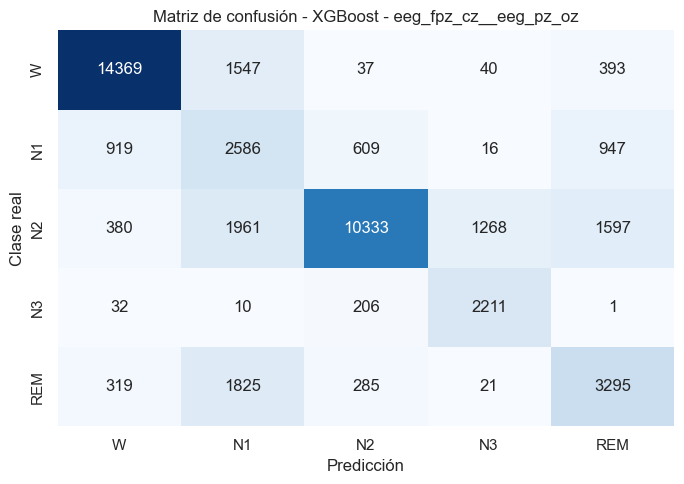

,W,N1,N2,N3,REM
W,14369,1547,37,40,393
N1,919,2586,609,16,947
N2,380,1961,10333,1268,1597
N3,32,10,206,2211,1
REM,319,1825,285,21,3295


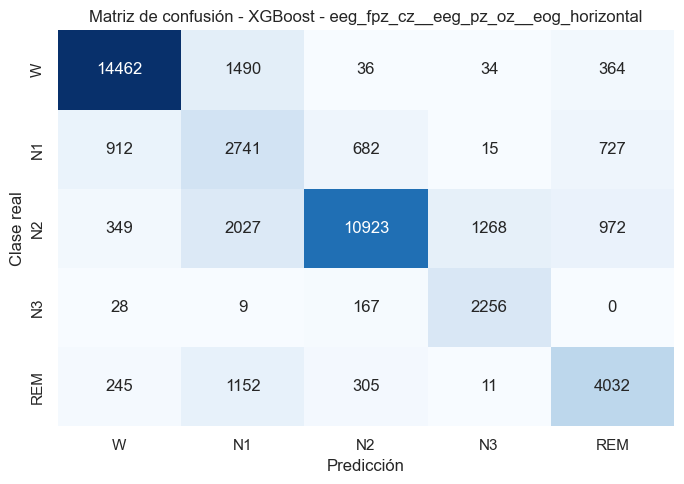

,W,N1,N2,N3,REM
W,14462,1490,36,34,364
N1,912,2741,682,15,727
N2,349,2027,10923,1268,972
N3,28,9,167,2256,0
REM,245,1152,305,11,4032


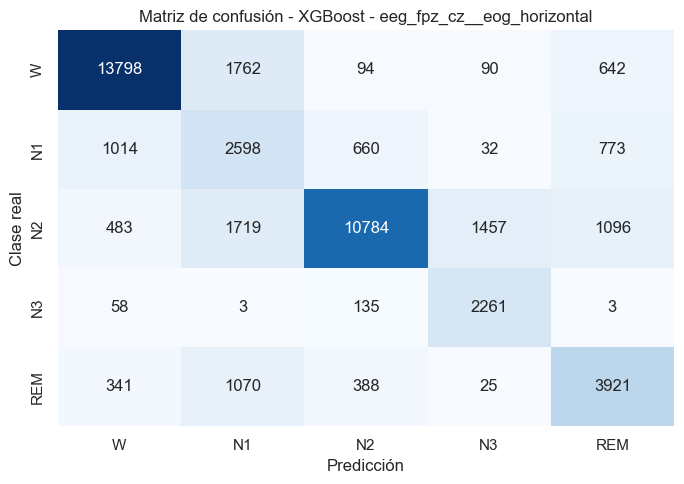

,W,N1,N2,N3,REM
W,13798,1762,94,90,642
N1,1014,2598,660,32,773
N2,483,1719,10784,1457,1096
N3,58,3,135,2261,3
REM,341,1070,388,25,3921


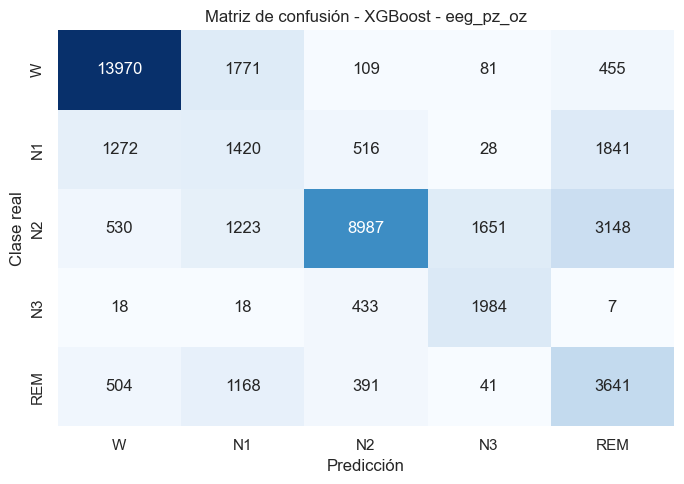

,W,N1,N2,N3,REM
W,13970,1771,109,81,455
N1,1272,1420,516,28,1841
N2,530,1223,8987,1651,3148
N3,18,18,433,1984,7
REM,504,1168,391,41,3641


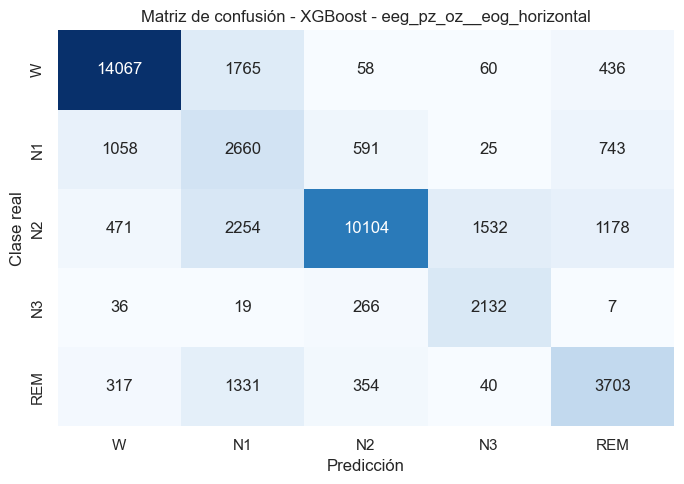

,W,N1,N2,N3,REM
W,14067,1765,58,60,436
N1,1058,2660,591,25,743
N2,471,2254,10104,1532,1178
N3,36,19,266,2132,7
REM,317,1331,354,40,3703


In [11]:
plot_confusion_matrices("XGBoost", xgb_test_eval_df)

### Importancia de variables y guardado de artefactos

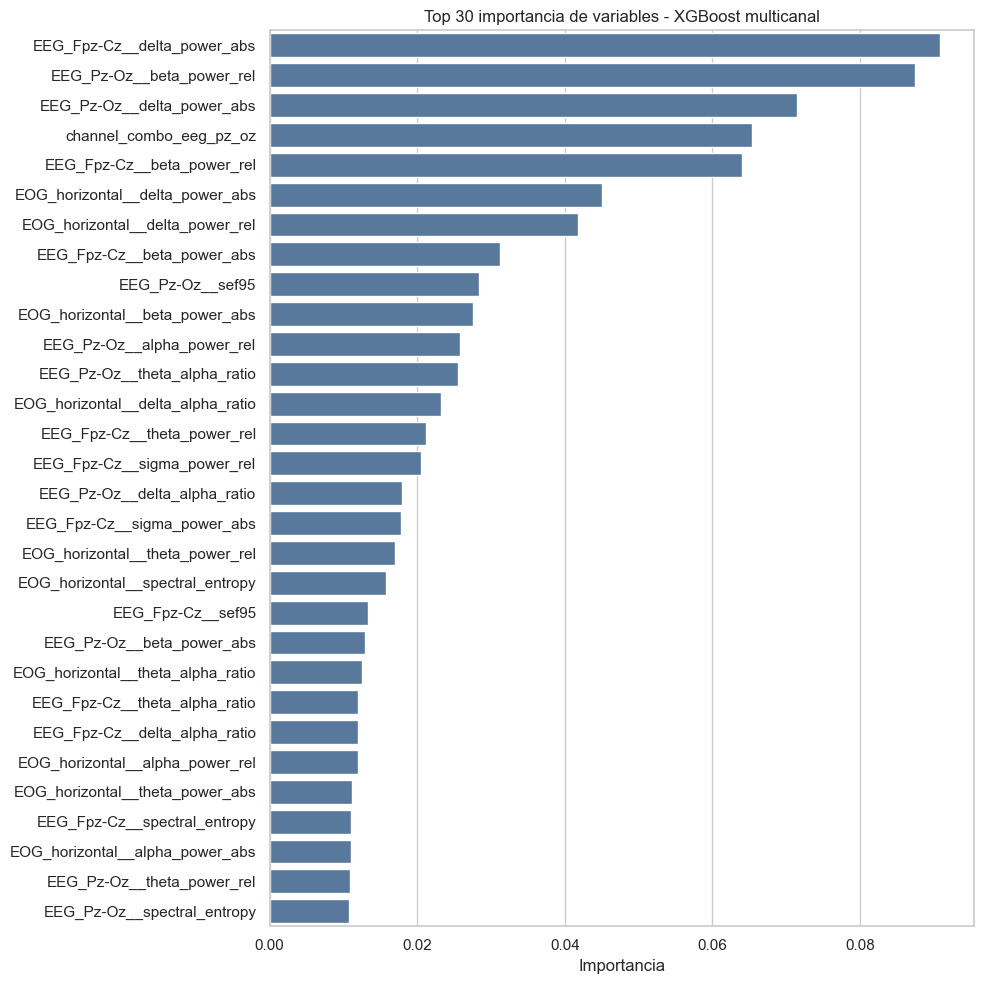

,feature,importance
9,EEG_Fpz-Cz__delta_power_abs,0.090898
21,EEG_Pz-Oz__beta_power_rel,0.087451
23,EEG_Pz-Oz__delta_power_abs,0.071460
50,channel_combo_eeg_pz_oz,0.065421
7,EEG_Fpz-Cz__beta_power_rel,0.064046
37,EOG_horizontal__delta_power_abs,0.045052
38,EOG_horizontal__delta_power_rel,0.041844
6,EEG_Fpz-Cz__beta_power_abs,0.031177
25,EEG_Pz-Oz__sef95,0.028331
34,EOG_horizontal__beta_power_abs,0.027573


Pipeline joblib guardado en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/best-xgboost-multicanal.joblib
Info guardada en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/model_info_xgboost_multicanal.json
Métricas por combinación guardadas en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/metrics_by_channel_combo_xgboost_multicanal.csv
Modelo XGBoost guardado en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/best-xgboost-multicanal-model.json


In [13]:
xgb_feature_importance = plot_feature_importance("XGBoost", xgb_search.best_estimator_)

xgb_paths = save_artifacts(
    "XGBoost",
    "xgboost",
    xgb_search,
    xgb_metrics,
    xgb_metrics_by_combo,
    xgb_per_class_by_combo,
    xgb_feature_importance,
)

# Formato nativo de XGBoost, además del joblib. Se guarda desde el Booster porque
# XGBClassifier.save_model() falla con scikit-learn >= 1.8 (`_estimator_type` undefined).
XGB_MODEL_PATH = MODEL_DIR / "best-xgboost-multicanal-model.json"
xgb_search.best_estimator_.get_booster().save_model(XGB_MODEL_PATH)
print(f"Modelo XGBoost guardado en: {XGB_MODEL_PATH}")

## Modelo 2: LightGBM

Gradient boosting con crecimiento de árboles por hoja. Se exploran número de árboles, tasa de aprendizaje, `num_leaves`, profundidad, tamaño mínimo de hoja, submuestreo de filas/columnas y regularización.

### Búsqueda de hiperparámetros

In [14]:
lgbm_model = LGBMClassifier(
    objective="multiclass",
    num_class=len(class_labels),
    subsample_freq=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)

lgbm_param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 5, 8, 12],
    "min_child_samples": [20, 50, 100, 200],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0, 0.5, 1.0, 2.0],
}

lgbm_search = run_search("LightGBM", lgbm_model, lgbm_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 2.5min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 2.5min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 2.5min
[CV] END learning_rate=0.03, max_depth=5, min_child_samples=50, n_estimators=200, num_leaves=15, reg_alpha=0.5, reg_lambda=1.0; total time= 1.0min
[CV] END learning_rate=0.03, max_depth=5, min_child_samples=50, n_estimators=200, num_leaves=15, reg_alpha=0.5, reg_lambda=1.0; total time=  59.9s
[CV] END learning_rate=0.03, max_depth=5, min_child_samples=50, n_estimators=200, num_leaves=15, reg_alpha=0.5, reg_lambda=1.0; total time= 1.0min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samp

{'reg_lambda': 0,
 'reg_alpha': 0.01,
 'num_leaves': 31,
 'n_estimators': 200,
 'min_child_samples': 20,
 'max_depth': 12,
 'learning_rate': 0.05}

In [15]:
lgbm_cv_results = show_cv_results(lgbm_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
4,1,0.684964,0.014537,0.766254,0.003154,"{'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav..."
8,2,0.684593,0.016307,0.799613,0.002420,"{'reg_lambda': 2.0, 'reg_alpha': 0.01, 'num_le..."
5,3,0.683302,0.015345,0.806889,0.002929,"{'reg_lambda': 0.5, 'reg_alpha': 0.1, 'num_lea..."
9,4,0.682734,0.016940,0.814418,0.002685,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'num_leave..."
7,5,0.681940,0.012610,0.738653,0.003442,"{'reg_lambda': 1.0, 'reg_alpha': 0.1, 'num_lea..."
2,6,0.676284,0.010695,0.722697,0.003785,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'num_lea..."
6,7,0.675184,0.018932,0.867126,0.001843,"{'reg_lambda': 1.0, 'reg_alpha': 0, 'num_leave..."
1,8,0.673801,0.011764,0.724851,0.003717,"{'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leave..."
3,9,0.671551,0.019284,0.896893,0.001667,"{'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leave..."
0,10,0.664084,0.019765,0.930264,0.001374,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'num_leave..."


### Evaluación global en test y por combinación de canales

=== LightGBM - evaluación global en test ===


accuracy                                                      0.710255
macro_f1                                                      0.650771
balanced_accuracy                                              0.69472
cohens_kappa                                                  0.610861
best_cv_macro_f1                                              0.684964
best_params          {'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.875840,0.844349,0.859806,98316
1,N1,0.322789,0.463299,0.380486,30462
2,N2,0.888736,0.652745,0.752676,93234
3,N3,0.563780,0.887534,0.689546,14760
4,REM,0.525691,0.625674,0.571342,34470


              precision    recall  f1-score   support

           W       0.32      0.46      0.38     30462
          N1       0.89      0.65      0.75     93234
          N2       0.56      0.89      0.69     14760
          N3       0.53      0.63      0.57     34470
         REM       0.88      0.84      0.86     98316

    accuracy                           0.71    271242
   macro avg       0.64      0.69      0.65    271242
weighted avg       0.76      0.71      0.72    271242



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,45207,0.664211,0.604235,0.655279,0.551658
2,eeg_fpz_cz__eeg_pz_oz,45207,0.723361,0.662806,0.702641,0.627840
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,45207,0.756188,0.704792,0.745607,0.671035
4,eeg_fpz_cz__eog_horizontal,45207,0.734577,0.682152,0.727661,0.642565
5,eeg_pz_oz,45207,0.662397,0.585990,0.628633,0.547799
6,eeg_pz_oz__eog_horizontal,45207,0.720795,0.666505,0.708500,0.625171
0,overall,271242,0.710255,0.650771,0.694720,0.610861


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.301364,0.422100,0.351657,5077
2,eeg_fpz_cz,N2,0.884508,0.629384,0.735449,15539
3,eeg_fpz_cz,N3,0.514503,0.908537,0.656966,2460
4,eeg_fpz_cz,REM,0.422977,0.535770,0.472738,5745
0,eeg_fpz_cz,W,0.829615,0.780605,0.804364,16386
6,eeg_fpz_cz__eeg_pz_oz,N1,0.322190,0.497341,0.391048,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.899609,0.665487,0.765037,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.603200,0.904065,0.723605,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.525920,0.572150,0.548062,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.898733,0.874161,0.886276,16386


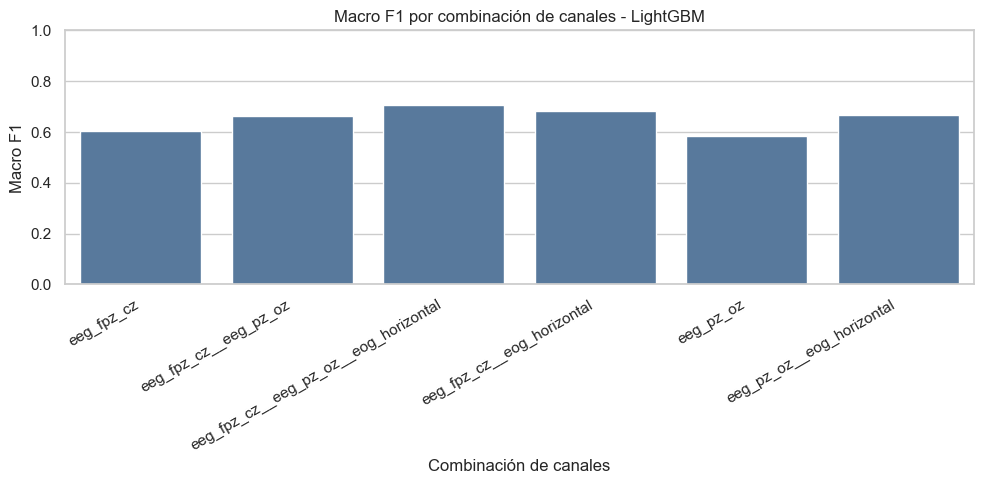

In [16]:
lgbm_y_pred, lgbm_metrics, lgbm_per_class = evaluate_global("LightGBM", lgbm_search)
lgbm_test_eval_df, lgbm_metrics_by_combo, lgbm_per_class_by_combo = evaluate_by_combo("LightGBM", lgbm_y_pred)

### Matriz de confusión global y por combinación

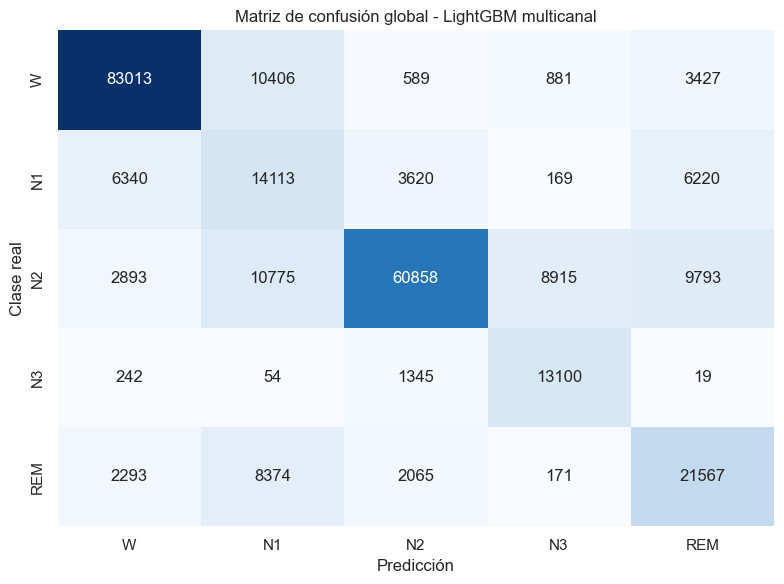

,W,N1,N2,N3,REM
W,83013,10406,589,881,3427
N1,6340,14113,3620,169,6220
N2,2893,10775,60858,8915,9793
N3,242,54,1345,13100,19
REM,2293,8374,2065,171,21567


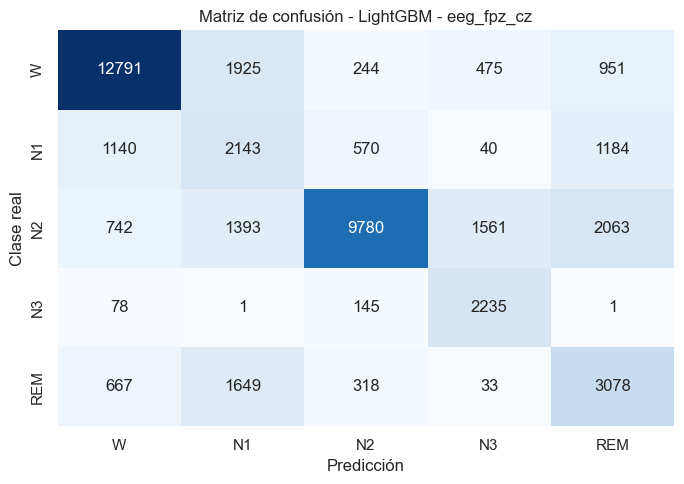

,W,N1,N2,N3,REM
W,12791,1925,244,475,951
N1,1140,2143,570,40,1184
N2,742,1393,9780,1561,2063
N3,78,1,145,2235,1
REM,667,1649,318,33,3078


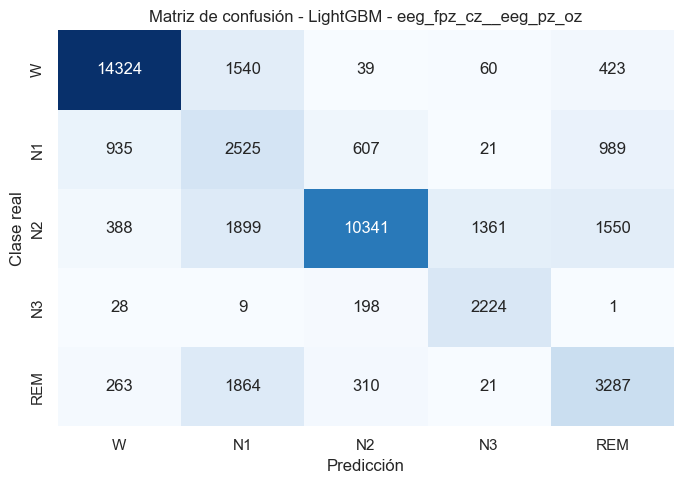

,W,N1,N2,N3,REM
W,14324,1540,39,60,423
N1,935,2525,607,21,989
N2,388,1899,10341,1361,1550
N3,28,9,198,2224,1
REM,263,1864,310,21,3287


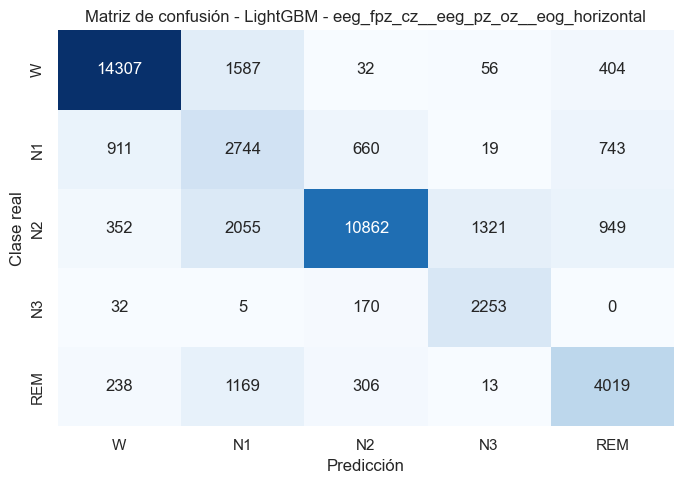

,W,N1,N2,N3,REM
W,14307,1587,32,56,404
N1,911,2744,660,19,743
N2,352,2055,10862,1321,949
N3,32,5,170,2253,0
REM,238,1169,306,13,4019


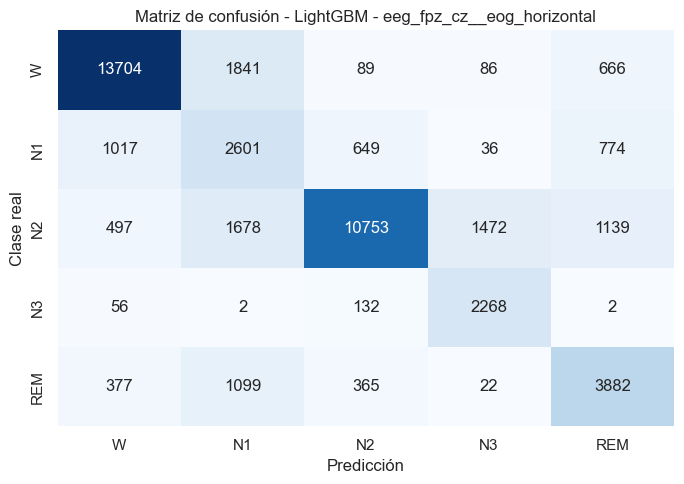

,W,N1,N2,N3,REM
W,13704,1841,89,86,666
N1,1017,2601,649,36,774
N2,497,1678,10753,1472,1139
N3,56,2,132,2268,2
REM,377,1099,365,22,3882


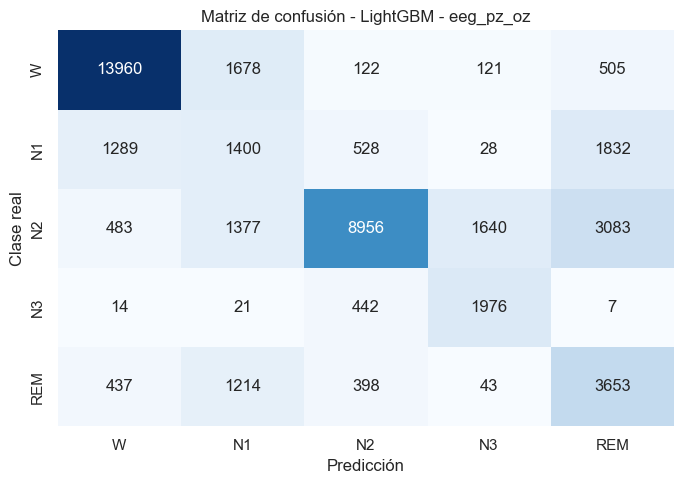

,W,N1,N2,N3,REM
W,13960,1678,122,121,505
N1,1289,1400,528,28,1832
N2,483,1377,8956,1640,3083
N3,14,21,442,1976,7
REM,437,1214,398,43,3653


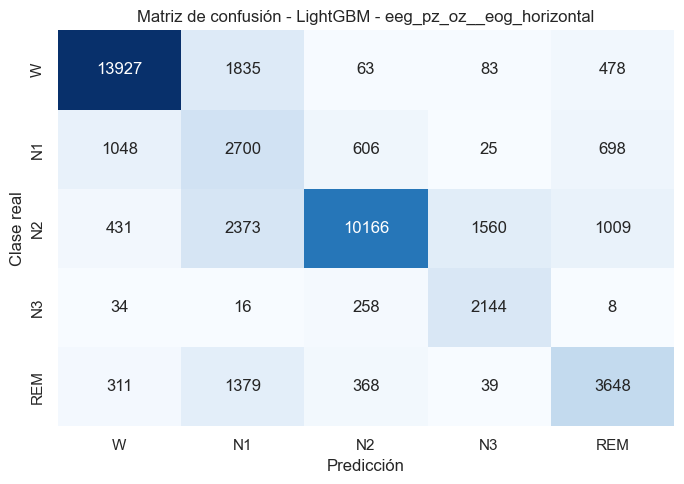

,W,N1,N2,N3,REM
W,13927,1835,63,83,478
N1,1048,2700,606,25,698
N2,431,2373,10166,1560,1009
N3,34,16,258,2144,8
REM,311,1379,368,39,3648


In [17]:
plot_confusion_matrices("LightGBM", lgbm_test_eval_df)

### Importancia de variables y guardado de artefactos

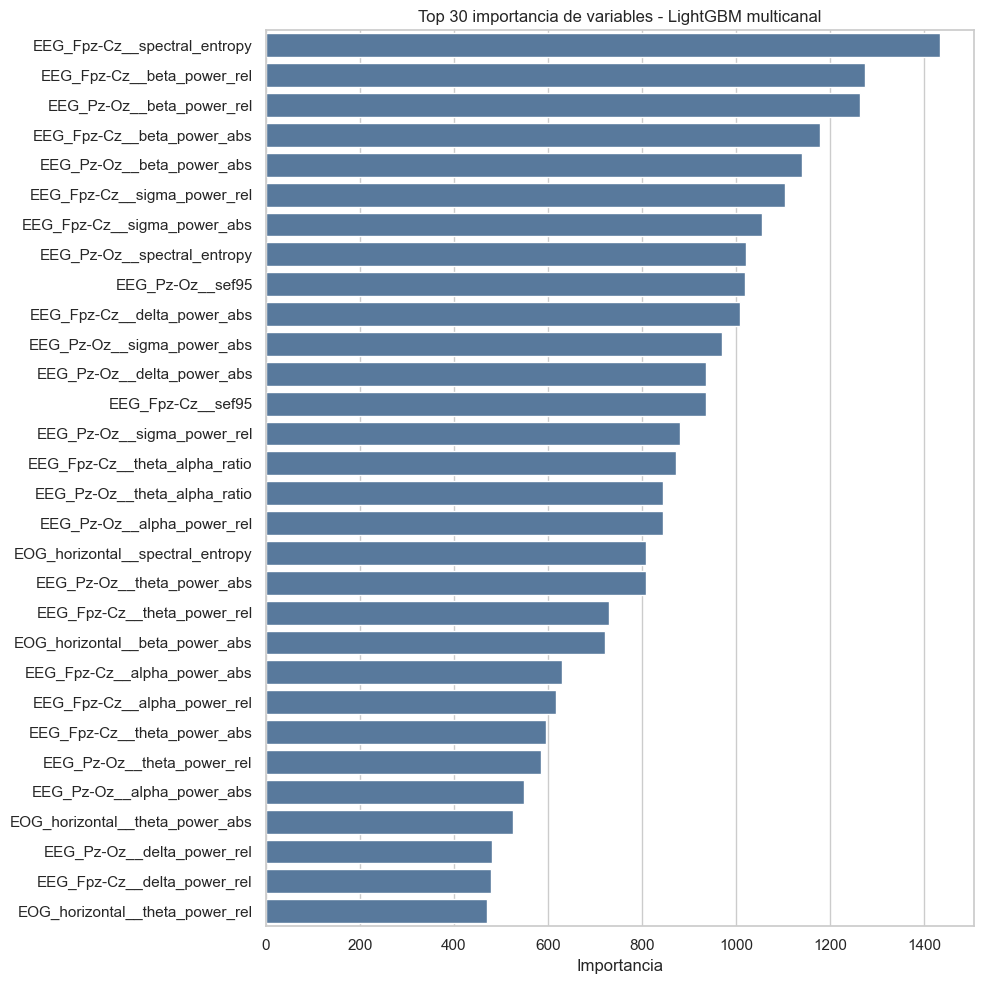

,feature,importance
14,EEG_Fpz-Cz__spectral_entropy,1435
7,EEG_Fpz-Cz__beta_power_rel,1275
21,EEG_Pz-Oz__beta_power_rel,1264
6,EEG_Fpz-Cz__beta_power_abs,1178
20,EEG_Pz-Oz__beta_power_abs,1141
13,EEG_Fpz-Cz__sigma_power_rel,1105
12,EEG_Fpz-Cz__sigma_power_abs,1055
28,EEG_Pz-Oz__spectral_entropy,1022
25,EEG_Pz-Oz__sef95,1020
9,EEG_Fpz-Cz__delta_power_abs,1009


Pipeline joblib guardado en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/best-lightgbm-multicanal.joblib
Info guardada en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/model_info_lightgbm_multicanal.json
Métricas por combinación guardadas en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/metrics_by_channel_combo_lightgbm_multicanal.csv


In [18]:
lgbm_feature_importance = plot_feature_importance("LightGBM", lgbm_search.best_estimator_)

lgbm_paths = save_artifacts(
    "LightGBM",
    "lightgbm",
    lgbm_search,
    lgbm_metrics,
    lgbm_metrics_by_combo,
    lgbm_per_class_by_combo,
    lgbm_feature_importance,
)

## Modelo 3: Random Forest

Ensamble de árboles por bagging. Se exploran número de árboles, profundidad, tamaños mínimos de división/hoja, número de variables por división y fracción de muestras por árbol.

### Búsqueda de hiperparámetros

In [ ]:
rf_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# `max_samples` limita la fracción de filas por árbol (bootstrap) para mantener
# el tiempo de entrenamiento razonable con ~900k épocas.
rf_param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, 20, 25],
    "min_samples_split": [10, 50, 100],
    "min_samples_leaf": [5, 20, 50],
    "max_features": ["sqrt", "log2"],
    "max_samples": [0.1, 0.2, 0.3],
}

rf_search = run_search("Random Forest", rf_model, rf_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


KeyboardInterrupt: 

In [ ]:
rf_cv_results = show_cv_results(rf_search)

### Evaluación global en test y por combinación de canales

In [ ]:
rf_y_pred, rf_metrics, rf_per_class = evaluate_global("Random Forest", rf_search)
rf_test_eval_df, rf_metrics_by_combo, rf_per_class_by_combo = evaluate_by_combo("Random Forest", rf_y_pred)

### Matriz de confusión global y por combinación

In [ ]:
plot_confusion_matrices("Random Forest", rf_test_eval_df)

### Importancia de variables y guardado de artefactos

In [ ]:
rf_feature_importance = plot_feature_importance("Random Forest", rf_search.best_estimator_)

rf_paths = save_artifacts(
    "Random Forest",
    "random-forest",
    rf_search,
    rf_metrics,
    rf_metrics_by_combo,
    rf_per_class_by_combo,
    rf_feature_importance,
)

## Modelo 4: Árbol de Decisión

Modelo base interpretable de un solo árbol. Se exploran criterio de división, profundidad, tamaños mínimos de división/hoja y número de variables por división.

### Búsqueda de hiperparámetros

In [ ]:
dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
)

dt_param_distributions = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 8, 10, 15, 20, None],
    "min_samples_split": [2, 10, 50, 100],
    "min_samples_leaf": [1, 5, 20, 50, 100],
    "max_features": [None, "sqrt", 0.5],
}

dt_search = run_search("Decision Tree", dt_model, dt_param_distributions)

In [ ]:
dt_cv_results = show_cv_results(dt_search)

### Evaluación global en test y por combinación de canales

In [ ]:
dt_y_pred, dt_metrics, dt_per_class = evaluate_global("Decision Tree", dt_search)
dt_test_eval_df, dt_metrics_by_combo, dt_per_class_by_combo = evaluate_by_combo("Decision Tree", dt_y_pred)

### Matriz de confusión global y por combinación

In [ ]:
plot_confusion_matrices("Decision Tree", dt_test_eval_df)

### Importancia de variables y guardado de artefactos

In [ ]:
dt_feature_importance = plot_feature_importance("Decision Tree", dt_search.best_estimator_)

dt_paths = save_artifacts(
    "Decision Tree",
    "decision-tree",
    dt_search,
    dt_metrics,
    dt_metrics_by_combo,
    dt_per_class_by_combo,
    dt_feature_importance,
)

## Comparación de modelos

Resumen de las métricas en test y del mejor `f1_macro` de validación cruzada para los cuatro modelos. El ranking se ordena por `macro_f1` en test.

In [ ]:
comparison = pd.DataFrame(
    [
        {
            "model": model_name,
            "best_cv_macro_f1": result["metrics"]["best_cv_macro_f1"],
            "accuracy": result["metrics"]["accuracy"],
            "macro_f1": result["metrics"]["macro_f1"],
            "balanced_accuracy": result["metrics"]["balanced_accuracy"],
            "cohens_kappa": result["metrics"]["cohens_kappa"],
            "best_params": result["metrics"]["best_params"],
        }
        for model_name, result in results.items()
    ]
).sort_values("macro_f1", ascending=False).reset_index(drop=True)

comparison.to_csv(COMPARISON_PATH, index=False)
display(comparison)

comparison_long = comparison.melt(
    id_vars="model",
    value_vars=["best_cv_macro_f1", "accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"],
    var_name="metric",
    value_name="value",
)

plt.figure(figsize=(12, 5))
sns.barplot(data=comparison_long, x="metric", y="value", hue="model")
plt.title("Comparación de modelos multicanal")
plt.xlabel("Métrica")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

best_model_name = comparison.loc[0, "model"]
print(f"Mejor modelo por macro F1 en test: {best_model_name} ({comparison.loc[0, 'macro_f1']:.4f})")
print(f"Comparación guardada en: {COMPARISON_PATH}")

In [ ]:
comparison_by_combo = pd.concat(
    [
        result["metrics_by_combo"].assign(model=model_name)
        for model_name, result in results.items()
    ],
    ignore_index=True,
)
comparison_by_combo.to_csv(COMPARISON_BY_COMBO_PATH, index=False)

display(
    comparison_by_combo.pivot(index="channel_combo", columns="model", values="macro_f1")
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=comparison_by_combo[comparison_by_combo["channel_combo"] != "overall"],
    x="channel_combo",
    y="macro_f1",
    hue="model",
)
plt.title("Macro F1 por combinación de canales y modelo")
plt.xlabel("Combinación de canales")
plt.ylabel("Macro F1")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"Comparación por combinación guardada en: {COMPARISON_BY_COMBO_PATH}")